# Superstore Sales Analysis

Analysis of Superstore sales to find what drives profit and losses.
The notebook answers four business questions about product categories, regions, best-selling products and seasonality, using pandas and matplotlib on 9,994 order lines from 2011–2014.

**Contents:** 1. Load and clean the data · 2. Four business questions · 3. Summary and recommendations

## 1. Load and clean the data

In [ ]:
import os

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd

os.makedirs("images", exist_ok=True)

In [2]:
# Download the public Kaggle dataset (cached locally by kagglehub) and load it
path = kagglehub.dataset_download("ishanshrivastava28/superstore-sales")
df = pd.read_csv(os.path.join(path, "Superstore.csv"), encoding="latin-1")
print(df.shape)

(9994, 21)


In [3]:
# Data quality checks
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())

Missing values: 0
Duplicated rows: 0


In [4]:
# Convert date columns from text to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d-%m-%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%d-%m-%Y")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

The data is clean: no missing values, no duplicated rows, and both date columns now have a proper `datetime64` type.

## 2. Business questions

### Q1. Which product category brings the most sales and profit?

In [5]:
category = df.groupby("Category")[["Sales", "Profit"]].sum().round(0)
category = category.sort_values("Profit", ascending=False)
print(category)

                    Sales    Profit
Category                           
Technology       836154.0  145455.0
Office Supplies  719047.0  122491.0
Furniture        742000.0   18451.0


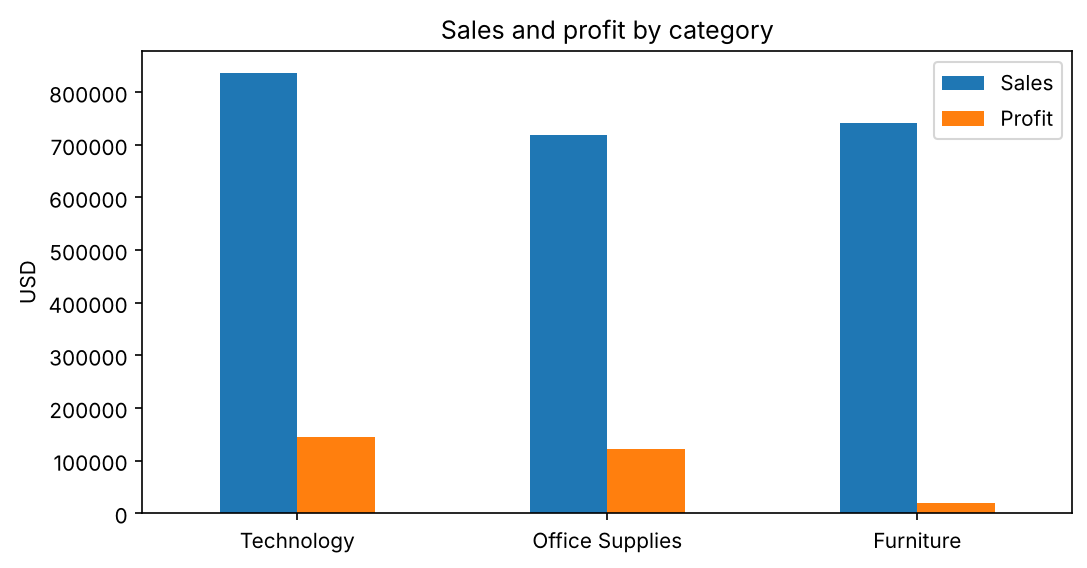

In [6]:
ax = category.plot(kind="bar", figsize=(8, 4), title="Sales and profit by category")
ax.set_xlabel("")
ax.set_ylabel("USD")
plt.xticks(rotation=0)
plt.savefig("images/profit_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** Technology leads in both sales ($836k) and profit ($145k), Office Supplies is a solid second ($122k profit), while Furniture sells as much as they do ($742k) but earns only $18k (a 2.5% margin).

### Q2. Which regions (and states) generate a loss?

**Step 1 – Regions:** sales, profit, average discount and profit margin per region.

In [7]:
region = df.groupby("Region").agg(
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
    avg_discount=("Discount", "mean"),
)
region["margin_%"] = (region["profit"] / region["sales"] * 100).round(1)
print(region.round(2).sort_values("margin_%"))

             sales     profit  avg_discount  margin_%
Region                                               
Central  501239.89   39706.36          0.24       7.9
South    391721.90   46749.43          0.15      11.9
East     678781.24   91522.78          0.15      13.5
West     725457.82  108418.45          0.11      14.9


**Step 2 – States:** the 5 states with the lowest profit.

In [8]:
state = df.groupby("State").agg(
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
    avg_discount=("Discount", "mean"),
)
print(state.round(2).sort_values("profit").head())

                    sales    profit  avg_discount
State                                            
Texas           170188.05 -25729.36          0.37
Ohio             78258.14 -16971.38          0.32
Pennsylvania    116511.91 -15559.96          0.33
Illinois         80166.10 -12607.89          0.39
North Carolina   55603.16  -7490.91          0.28


**Step 3 – Discounts:** average profit per order, grouped by discount level.

In [9]:
df["discount_group"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 1],
    labels=["0%", "1-20%", "21-40%", ">40%"],
)
by_discount = df.groupby("discount_group", observed=True)["Profit"].agg(["sum", "mean", "count"])
print("Total profit:", df["Profit"].sum().round(0))
print(by_discount.round(1))

Total profit: 286397.0
discount_group                        
0%              320987.6   66.9   4798
1-20%           100785.5   26.5   3803
21-40%          -35817.5  -77.9    460
>40%            -99558.6 -106.7    933


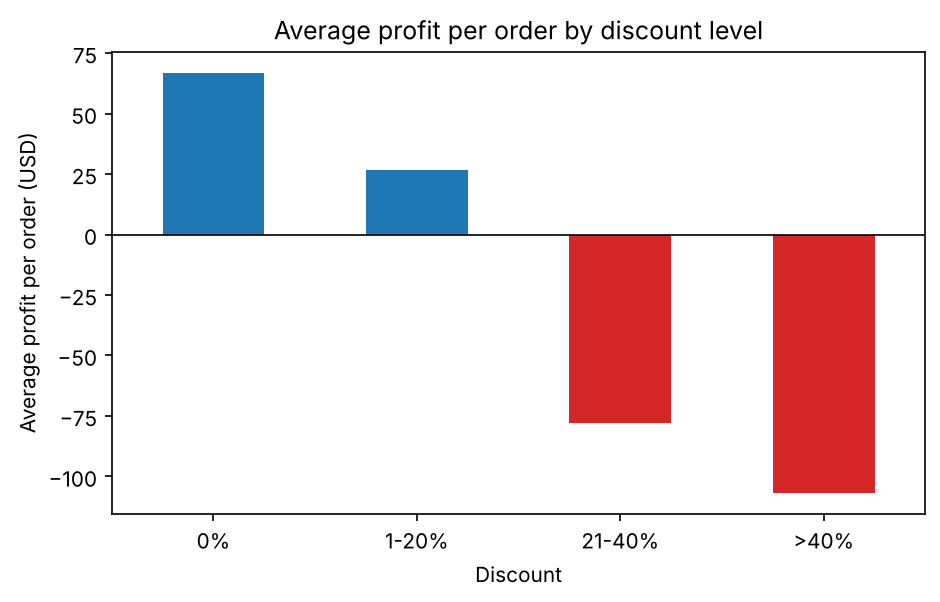

In [10]:
colors = ["#d62728" if v < 0 else "#1f77b4" for v in by_discount["mean"]]
ax = by_discount["mean"].plot(kind="bar", color=colors, figsize=(7, 4),
                              title="Average profit per order by discount level")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Discount")
ax.set_ylabel("Average profit per order (USD)")
plt.xticks(rotation=0)
plt.savefig("images/discount_vs_profit.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:** No region is loss-making overall, but Central has the lowest margin (7.9%) and the highest average discount (24%), and losses concentrate in a few states (Texas −$25.7k, Ohio −$17.0k, Pennsylvania −$15.6k) where average discounts are 32–37%, with orders discounted above 20% losing money on average (−$78 and −$107 per order).

### Q3. What are the 10 best-selling products, and do they make money?

In [11]:
products = df.groupby("Product Name").agg(
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
)
products["margin_%"] = (products["profit"] / products["sales"] * 100).round(1)
print(products.nlargest(10, "sales").round(0))

                                                      sales   profit  margin_%
Product Name                                                                  
Canon imageCLASS 2200 Advanced Copier               61600.0  25200.0      41.0
Fellowes PB500 Electric Punch Plastic Comb Bind...  27453.0   7753.0      28.0
Cisco TelePresence System EX90 Videoconferencin...  22638.0  -1811.0      -8.0
HON 5400 Series Task Chairs for Big and Tall        21871.0      0.0       0.0
GBC DocuBind TL300 Electric Binding System          19823.0   2234.0      11.0
GBC Ibimaster 500 Manual ProClick Binding System    19024.0    761.0       4.0
Hewlett Packard LaserJet 3310 Copier                18840.0   6984.0      37.0
HP Designjet T520 Inkjet Large Format Printer -...  18375.0   4095.0      22.0
GBC DocuBind P400 Electric Binding System           17965.0  -1878.0     -10.0
High Speed Automatic Electric Letter Opener         17030.0   -262.0      -2.0


**Conclusion:** Best-sellers are not always top earners: 3 of the 10 products lose money (Cisco TelePresence EX90, GBC DocuBind P400, High Speed Letter Opener) and the HON 5400 chairs earn roughly nothing on $21.9k of sales, while the Canon imageCLASS 2200 copier earns $25.2k at a 41% margin.

### Q4. How do sales change over time?

**Monthly sales, 2011–2014:**

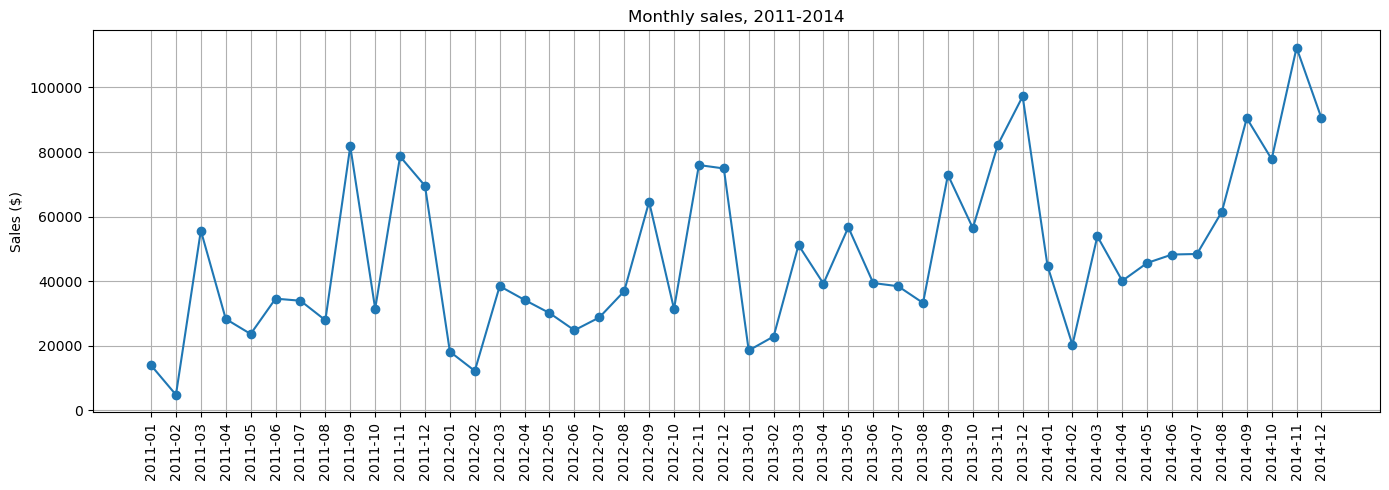

In [12]:
df["month"] = df["Order Date"].dt.to_period("M")
monthly = df.groupby("month")["Sales"].sum()

monthly.index = monthly.index.strftime("%Y-%m")
ax = monthly.plot(figsize=(14, 5), marker="o", grid=True, title="Monthly sales, 2011-2014")
ax.set_xticks(range(len(monthly)))
ax.set_xticklabels(monthly.index, rotation=90)
ax.set_xlabel("")
ax.set_ylabel("Sales ($)")
plt.tight_layout()
plt.show()

**Same data, one line per year (to compare seasonality):**

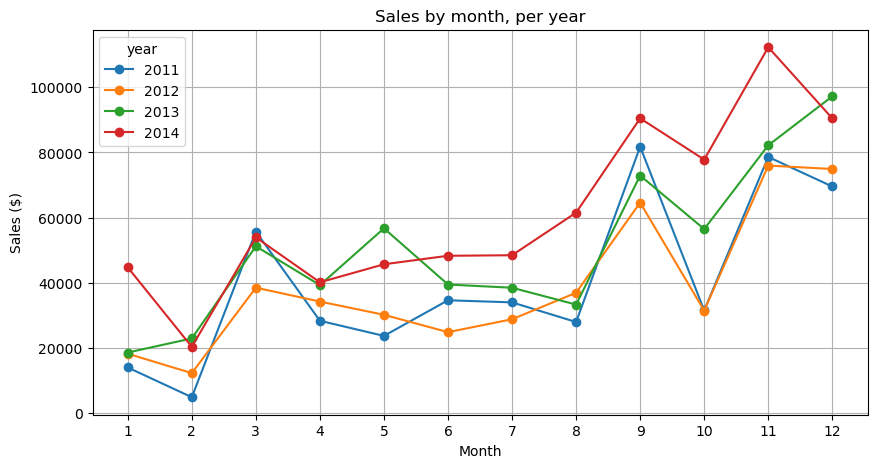

year          2011     2012     2013      2014
month_num                                     
1          13946.0  18174.0  18542.0   44703.0
2           4811.0  12211.0  22868.0   20284.0
3          55691.0  38467.0  51186.0   53909.0
4          28295.0  34195.0  39249.0   40112.0
5          23648.0  30132.0  56691.0   45651.0
6          34595.0  24797.0  39430.0   48260.0
7          33946.0  28765.0  38441.0   48428.0
8          27909.0  36898.0  33266.0   61516.0
9          81777.0  64596.0  72908.0   90489.0
10         31453.0  31405.0  56463.0   77794.0
11         78629.0  75973.0  82192.0  112326.0
12         69546.0  74920.0  97237.0   90475.0


In [13]:
df["year"] = df["Order Date"].dt.year
df["month_num"] = df["Order Date"].dt.month

pivot = df.pivot_table(index="month_num", columns="year", values="Sales", aggfunc="sum")
pivot.plot(figsize=(10, 5), marker="o", grid=True, title="Sales by month, per year")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.xticks(range(1, 13))
plt.savefig("images/sales_by_month.png", dpi=150, bbox_inches="tight")
plt.show()
print(pivot.round(0))

**Total yearly sales (in $ thousands):**

In [14]:
print((pivot.sum() / 1000).round(0))

year
2011    484.0
2012    471.0
2013    608.0
2014    734.0
dtype: float64


**Conclusion:** Sales are strongly seasonal, with a weak January–February, a small bump in March and peaks in September and November every year, and they trend upward overall (about $484k in 2011 to $734k in 2014, with a small dip in 2012), although the causes behind the seasonality (e.g. holidays, back-to-school) remain hypotheses.

## 3. Summary and recommendations

**Main findings**

1. **Technology and Office Supplies drive profit.** Furniture has high sales ($742k) but a very low margin (2.5%).
2. **Discounts are the main driver of losses.** Orders discounted above 20% lose money on average (−$78 per order at 21–40%, −$107 above 40%), while undiscounted orders earn +$67 each.
3. **Central has the weakest region margin (7.9%) and the highest discounts (24%).** Texas, Ohio and Pennsylvania are the biggest loss-making states.
4. **Sales are seasonal and growing.** Peaks in September and November repeat every year; January–February are the weakest months.

**Recommendations**

- Review and cap discounts above 20%, starting with Texas, Ohio, Pennsylvania and Illinois, then re-check profit after the change.
- Investigate Furniture pricing and costs to lift its margin closer to the other categories (about 17%).
- Reprice or reconsider best-selling products that lose money (Cisco TelePresence EX90, GBC DocuBind P400, High Speed Letter Opener).
- Plan stock and marketing around the September–November peak and run promotions to lift the weak January–February period.

*Note: these are patterns in historical data, not proven causes. Discount impact should be confirmed with a controlled test (e.g. a pilot in one state).*